<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_6_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Carica il dataset della produzione di energia rinnovabile
df_renewable_energy = pd.read_csv('/content/Renewable_Electricity_Production_Dataset.csv')

# Visualizza le prime 5 righe del DataFrame
display(df_renewable_energy.head())

,Country and area,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,67.73,67.98,67.99,68.35,68.70,69.04,70.37,72.39,74.44,...,85.32,86.07,86.15,84.70,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,87.61,95.07,95.89,95.12,96.62,95.24,96.63,96.99,97.10,...,100.00,100.00,100.00,100.78,100.0,99.74,99.71,100.00,99.79,100.00
2,Algeria,0.84,1.69,1.09,1.82,0.83,0.98,0.63,0.35,0.42,...,0.40,0.32,0.25,0.84,NaN,NaN,NaN,NaN,NaN,NaN
3,Andorra,100.0,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,88.98,86.87,84.85,83.82,84.5,83.92,83.95,83.74,83.35,83.34
4,Angola,86.21,82.66,88.70,93.68,93.72,93.75,89.98,76.35,80.42,...,53.18,53.18,56.12,71.40,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
eu_countries = [
    'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark',
    'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland', 'Italy',
    'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland', 'Portugal',
    'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden'
]

df_eu = df_renewable_energy[df_renewable_energy['Country and area'].isin(eu_countries)].copy()

# Convertire il DataFrame da formato 'wide' a 'long'
df_eu_long = df_eu.melt(id_vars=['Country and area'], var_name='Year', value_name='Renewable Energy Production')

# Convertire la colonna 'Year' in tipo numerico e la colonna 'Renewable Energy Production' in tipo float
df_eu_long['Year'] = pd.to_numeric(df_eu_long['Year'], errors='coerce')
df_eu_long['Renewable Energy Production'] = pd.to_numeric(df_eu_long['Renewable Energy Production'], errors='coerce')

# Visualizza le prime 5 righe del DataFrame filtrato e trasformato
display(df_eu_long.head())

,Country and area,Year,Renewable Energy Production
0,Austria,1990,64.63
1,Belgium,1990,1.27
2,Bulgaria,1990,4.46
3,Croatia,1990,NaN
4,Cyprus,1990,NaN


In [ ]:
# Controlla la quantità di valori mancanti
missing_values_count = df_eu_long.isnull().sum()
print("Valori mancanti per colonna:\n", missing_values_count)

# Gestire i valori mancanti: imputazione con interpolazione lineare
# Questo è un approccio comune per i dati di serie temporali
df_eu_long['Renewable Energy Production'] = df_eu_long.groupby('Country and area')['Renewable Energy Production'].transform(lambda group: group.interpolate(method='linear', limit_direction='both'))

# Rimuovere eventuali righe rimanenti con NaN (nel caso in cui un'intera serie temporale per un paese sia NaN)
df_eu_long.dropna(inplace=True)

# Verifica nuovamente i valori mancanti dopo l'imputazione
print("\nValori mancanti dopo l'imputazione:\n", df_eu_long.isnull().sum())

# Visualizza le prime righe del DataFrame dopo l'imputazione
display(df_eu_long.head())

Valori mancanti per colonna:
 Country and area                0
Year                            0
Renewable Energy Production    43
dtype: int64

Valori mancanti dopo l'imputazione:
 Country and area               0
Year                           0
Renewable Energy Production    0
dtype: int64


,Country and area,Year,Renewable Energy Production
0,Austria,1990,64.63
1,Belgium,1990,1.27
2,Bulgaria,1990,4.46
3,Croatia,1990,48.85
4,Cyprus,1990,0.02


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Preparazione dei dati per la modellazione
# Creare variabili dummy per i paesi
df_eu_processed = pd.get_dummies(df_eu_long, columns=['Country and area'], drop_first=True)

# Scalare la colonna 'Year'
scaler_year = StandardScaler()
df_eu_processed['Year_scaled'] = scaler_year.fit_transform(df_eu_processed[['Year']])

# Definire gli anni futuri per la previsione (fino al 2035)
future_years = np.arange(df_eu_processed['Year'].max() + 1, 2036).reshape(-1, 1)
future_years_scaled = scaler_year.transform(future_years)

# Inizializzare un DataFrame per memorizzare le previsioni
predictions_df = pd.DataFrame(columns=['Country', 'Year', 'Linear_Regression_Prediction'])

# Funzione per addestrare il modello di Regressione Lineare e fare previsioni
for country in df_eu_long['Country and area'].unique():
    df_country = df_eu_processed[df_eu_long['Country and area'] == country].copy()

    X_train = df_country[['Year_scaled']].values
    y_train = df_country['Renewable Energy Production'].values

    # Addestramento del modello di Regressione Lineare
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # Generare le previsioni per gli anni futuri
    country_future_data = pd.DataFrame({'Year': future_years.flatten()})
    country_future_data['Year_scaled'] = future_years_scaled
    lr_predictions = lr_model.predict(country_future_data[['Year_scaled']])

    # Aggiungere le previsioni al DataFrame
    temp_df = pd.DataFrame({
        'Country': country,
        'Year': future_years.flatten(),
        'Linear_Regression_Prediction': lr_predictions
    })
    predictions_df = pd.concat([predictions_df, temp_df], ignore_index=True)

# Visualizza le prime righe delle previsioni di Regressione Lineare
display(predictions_df.head())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
/tmp/ipykernel_1657/1549058497.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  predictions_df = pd.concat([predictions_df, temp_df], ignore_index=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklea

,Country,Year,Linear_Regression_Prediction
0,Austria,2024,69.704759
1,Austria,2025,69.836309
2,Austria,2026,69.967858
3,Austria,2027,70.099407
4,Austria,2028,70.230956


In [ ]:
# Aggiungere colonne per le previsioni di Regressione Polinomiale
predictions_df['Polynomial_Regression_Prediction'] = np.nan

# Funzione per addestrare il modello di Regressione Polinomiale e fare previsioni
for country in df_eu_long['Country and area'].unique():
    df_country = df_eu_processed[df_eu_long['Country and area'] == country].copy()

    X_train = df_country[['Year_scaled']].values
    y_train = df_country['Renewable Energy Production'].values

    # Trasformazione polinomiale delle feature
    poly_features = PolynomialFeatures(degree=2) # Grado 2 per iniziare, può essere ottimizzato
    X_poly_train = poly_features.fit_transform(X_train)
    future_years_poly_scaled = poly_features.transform(future_years_scaled)

    # Addestramento del modello di Regressione Polinomiale
    poly_model = LinearRegression()
    poly_model.fit(X_poly_train, y_train)

    # Generare le previsioni per gli anni futuri
    poly_predictions = poly_model.predict(future_years_poly_scaled)

    # Aggiornare il DataFrame delle previsioni
    predictions_df.loc[predictions_df['Country'] == country, 'Polynomial_Regression_Prediction'] = poly_predictions

# Visualizza le prime righe delle previsioni di Regressione Polinomiale
display(predictions_df.head())

,Country,Year,Linear_Regression_Prediction,Polynomial_Regression_Prediction
0,Austria,2024,69.704759,73.560692
1,Austria,2025,69.836309,74.353258
2,Austria,2026,69.967858,75.182548
3,Austria,2027,70.099407,76.048560
4,Austria,2028,70.230956,76.951296


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Aggiungere colonne per le previsioni di LSTM
predictions_df['LSTM_Prediction'] = np.nan

# Loop per ogni paese per addestrare il modello LSTM e fare previsioni
for country in df_eu_long['Country and area'].unique():
    df_country = df_eu_processed[df_eu_long['Country and area'] == country].copy()

    # Preparazione dei dati per LSTM
    # Scalare la produzione di energia rinnovabile per l'LSTM (spesso migliora le performance)
    scaler_production = MinMaxScaler(feature_range=(0, 1))
    y_train_scaled = scaler_production.fit_transform(df_country[['Renewable Energy Production']])

    # Input: Anni scalati. Output: Produzione scalata.
    # Per LSTM, l'input deve essere [samples, timesteps, features]. Qui usiamo timesteps=1 e features=1 (Year_scaled)
    X_lstm_train = df_country[['Year_scaled']].values.reshape(-1, 1, 1)

    # Costruzione del modello LSTM
    lstm_model = Sequential()
    lstm_model.add(LSTM(units=50, activation='relu', input_shape=(1, 1)))
    lstm_model.add(Dense(units=1))
    lstm_model.compile(optimizer='adam', loss='mean_squared_error')

    # Addestramento del modello LSTM
    lstm_model.fit(X_lstm_train, y_train_scaled, epochs=100, batch_size=1, verbose=0)

    # Preparare gli anni futuri per la previsione LSTM
    future_years_lstm_scaled = future_years_scaled.reshape(-1, 1, 1)

    # Generare le previsioni per gli anni futuri
    lstm_predictions_scaled = lstm_model.predict(future_years_lstm_scaled, verbose=0)

    # Invertire la scalatura per ottenere i valori originali
    lstm_predictions = scaler_production.inverse_transform(lstm_predictions_scaled)

    # Aggiornare il DataFrame delle previsioni
    predictions_df.loc[predictions_df['Country'] == country, 'LSTM_Prediction'] = lstm_predictions.flatten()

# Visualizza le prime righe delle previsioni complete
display(predictions_df.head())

# Visualizza l'intero DataFrame delle previsioni
display(predictions_df)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a l

,Country,Year,Linear_Regression_Prediction,Polynomial_Regression_Prediction,LSTM_Prediction
0,Austria,2024,69.704759,73.560692,70.394096
1,Austria,2025,69.836309,74.353258,70.300400
2,Austria,2026,69.967858,75.182548,70.191681
3,Austria,2027,70.099407,76.048560,70.068260
4,Austria,2028,70.230956,76.951296,69.933212


,Country,Year,Linear_Regression_Prediction,Polynomial_Regression_Prediction,LSTM_Prediction
0,Austria,2024,69.704759,73.560692,70.394096
1,Austria,2025,69.836309,74.353258,70.300400
2,Austria,2026,69.967858,75.182548,70.191681
3,Austria,2027,70.099407,76.048560,70.068260
4,Austria,2028,70.230956,76.951296,69.933212
...,...,...,...,...,...
307,Sweden,2031,52.054011,57.558850,49.845291
308,Sweden,2032,52.225867,58.276822,49.646774
309,Sweden,2033,52.397723,59.016638,49.434311
310,Sweden,2034,52.569580,59.778298,49.208546


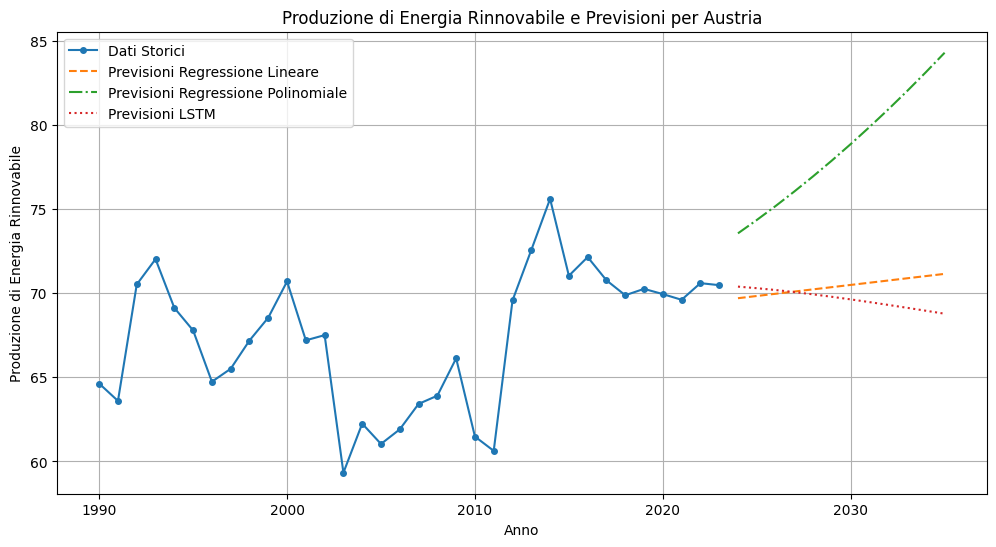

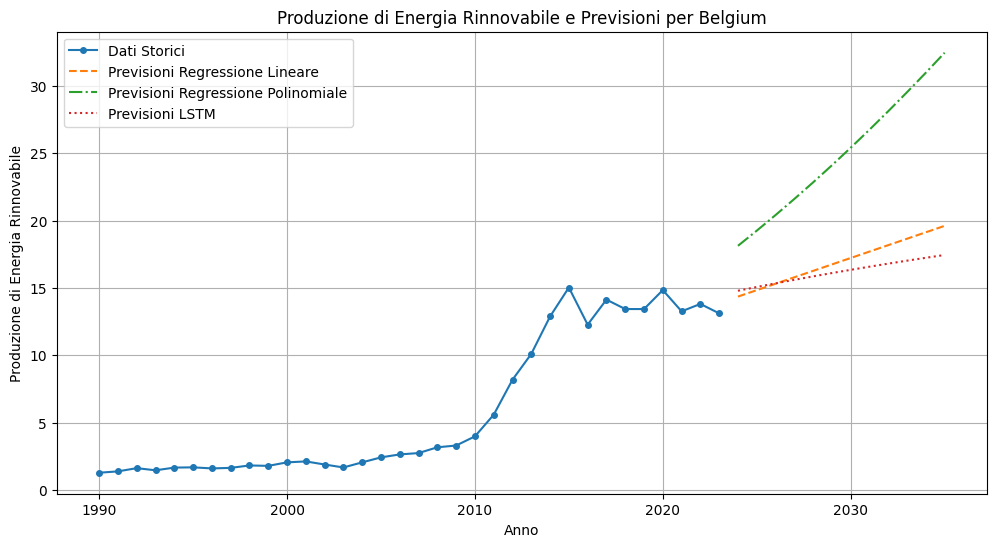

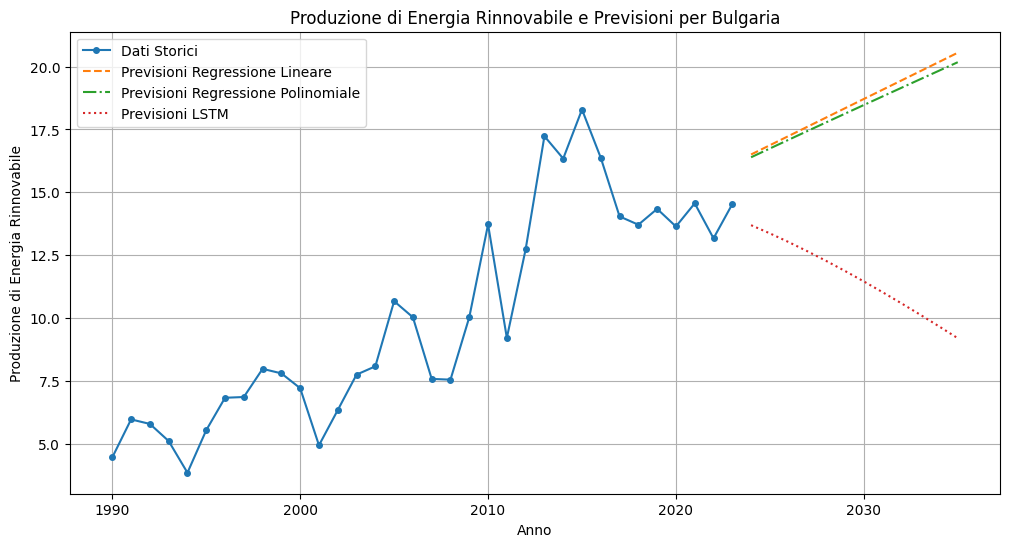

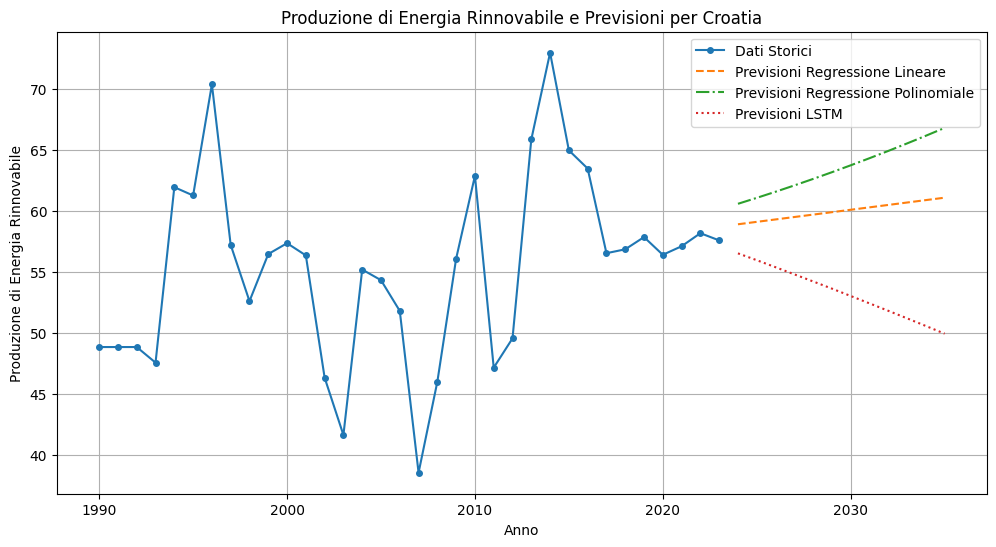

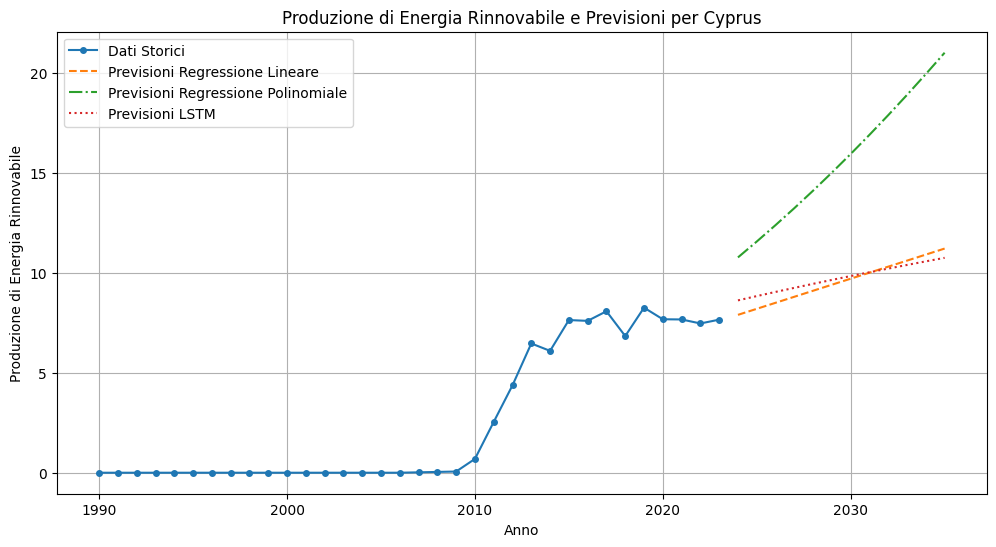

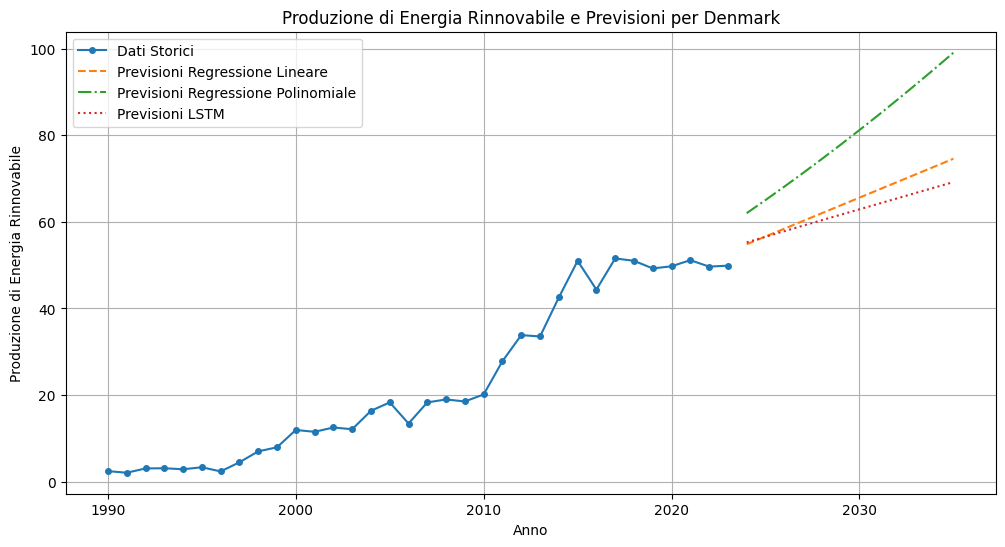

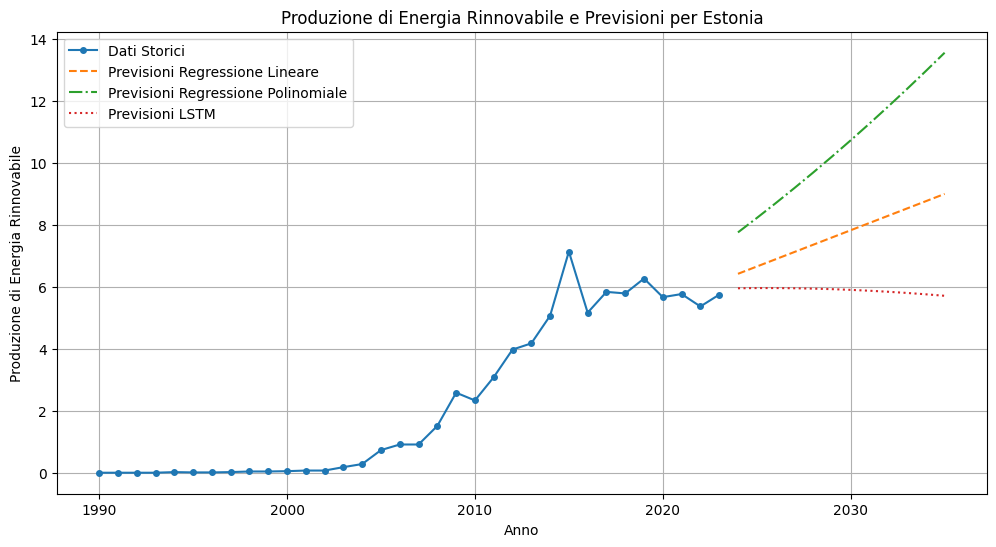

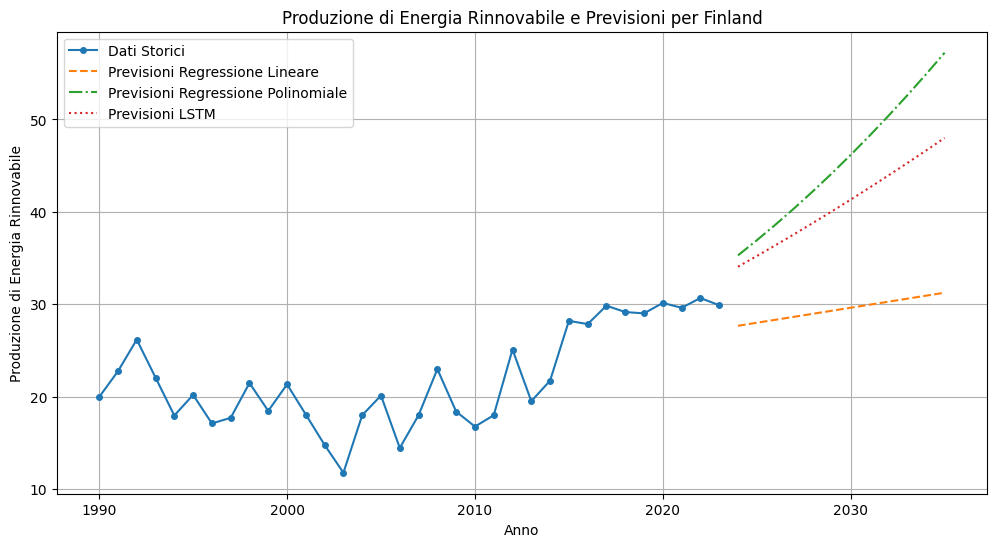

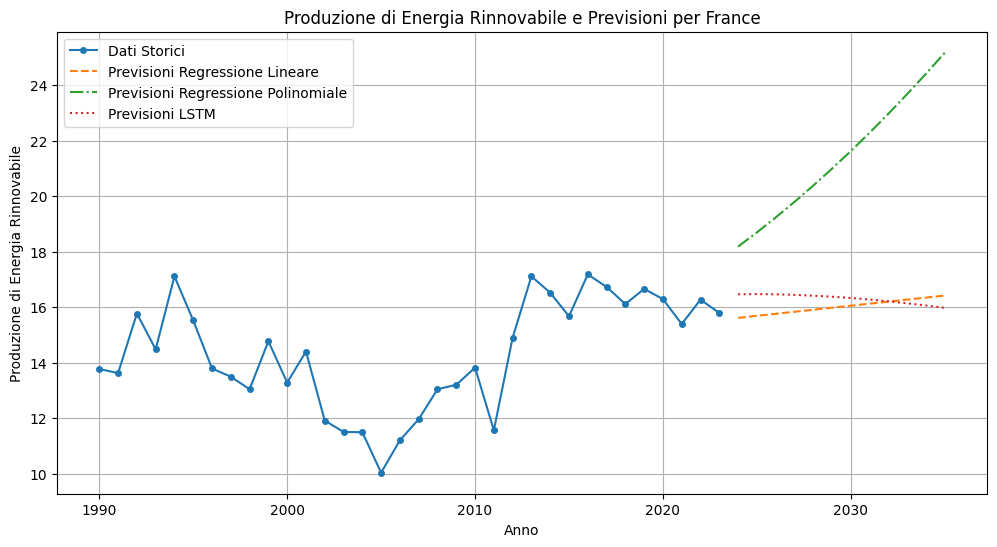

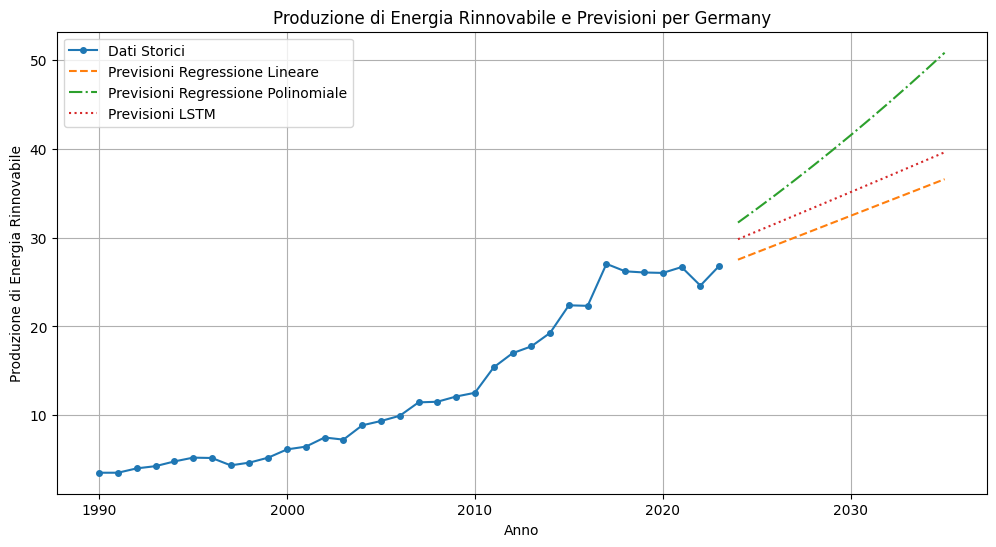

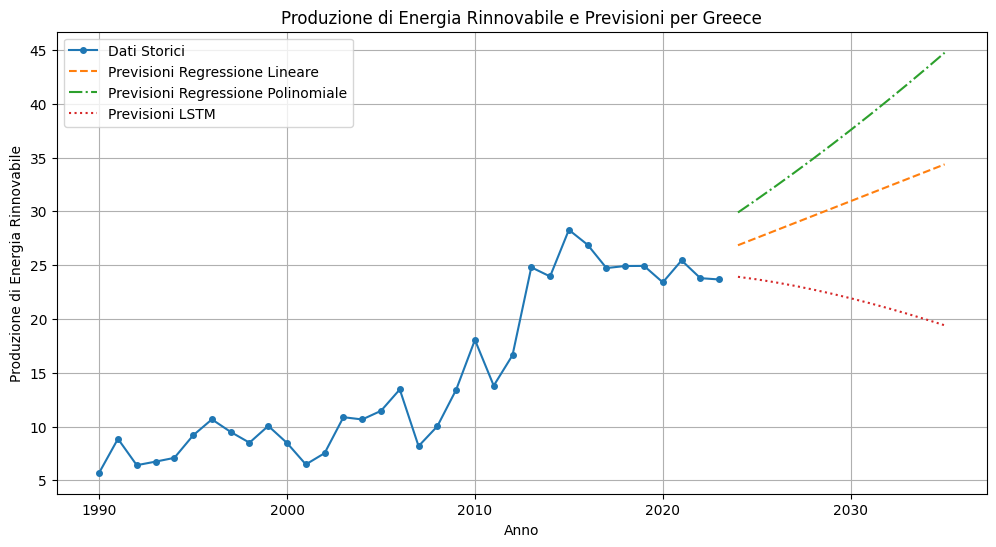

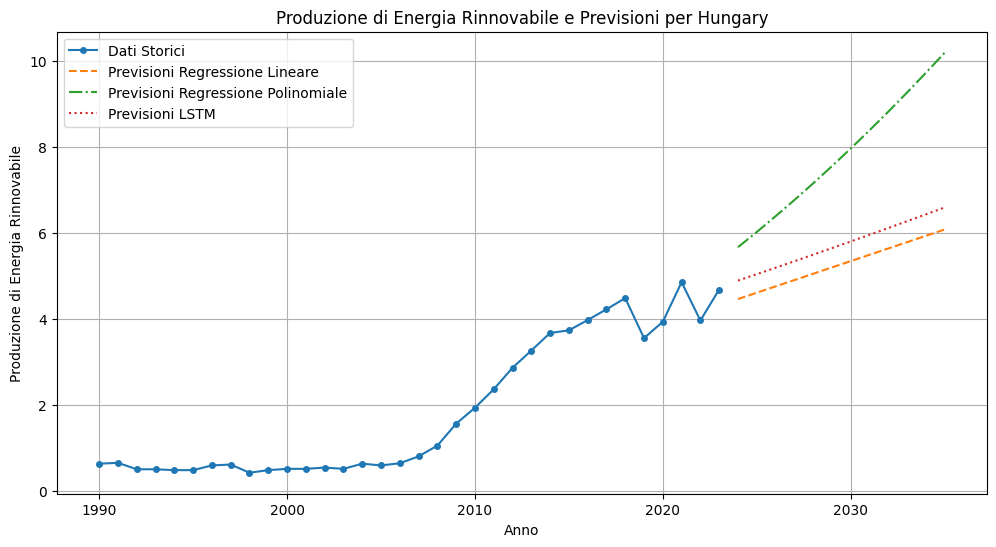

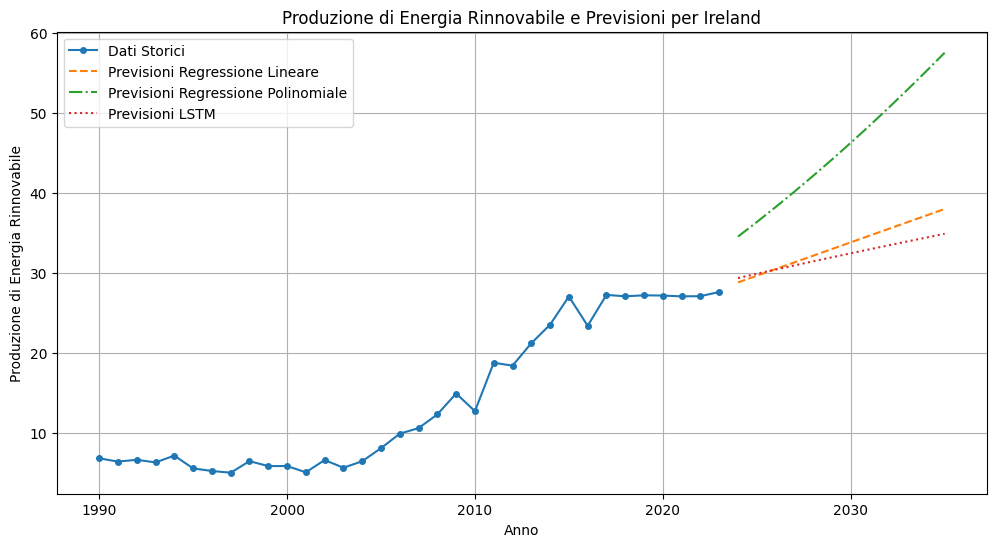

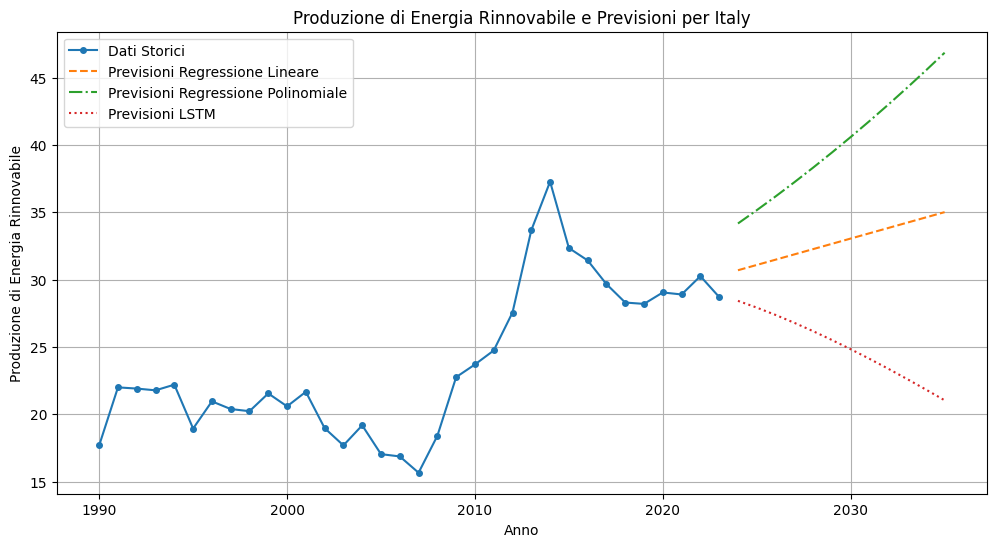

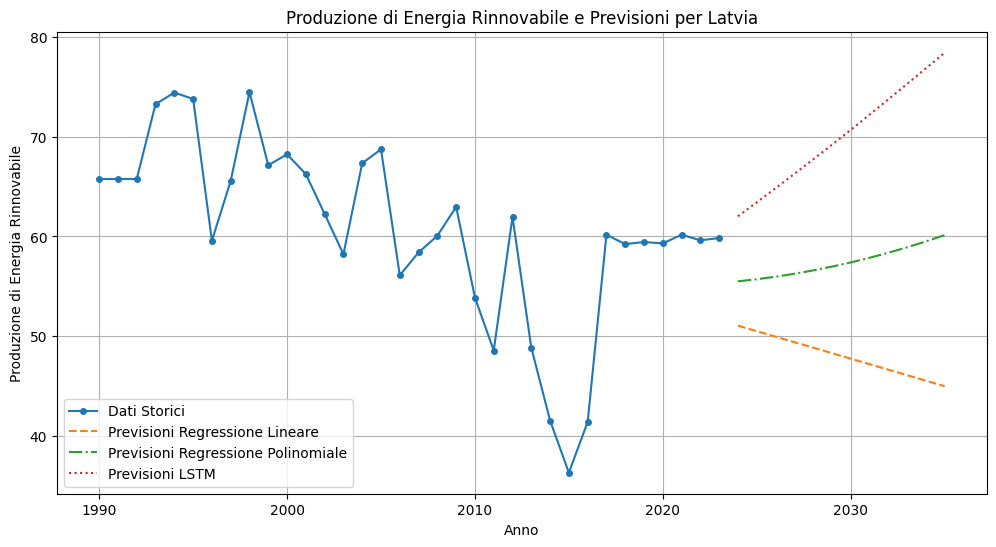

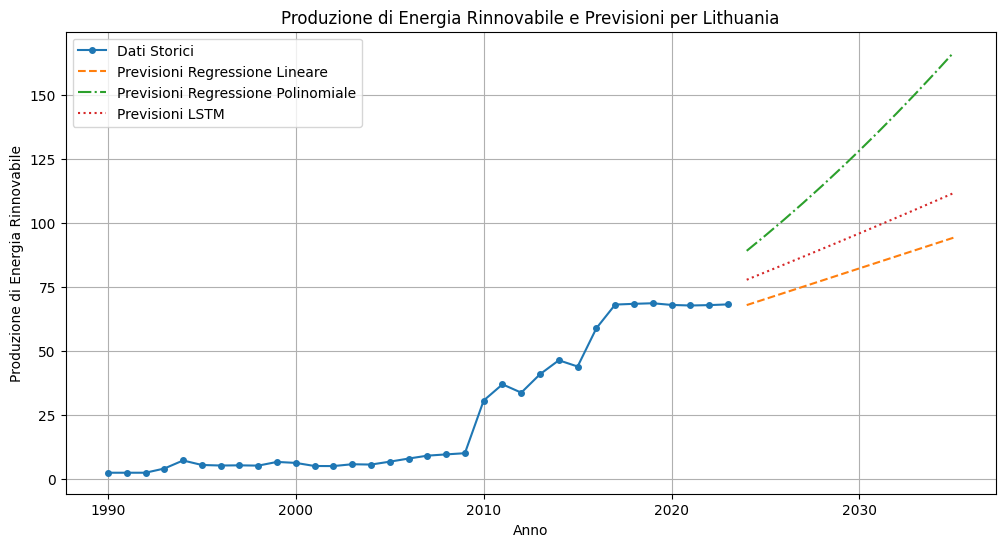

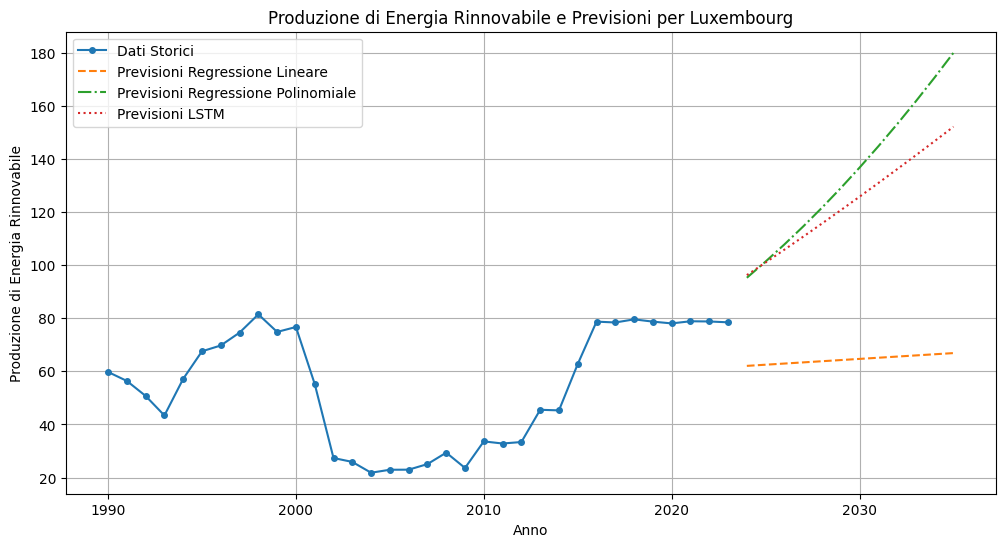

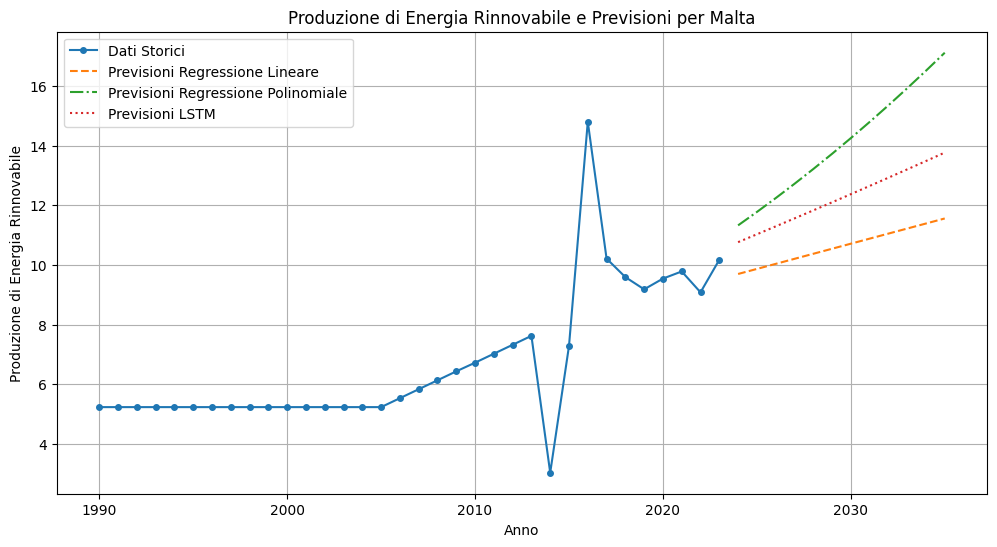

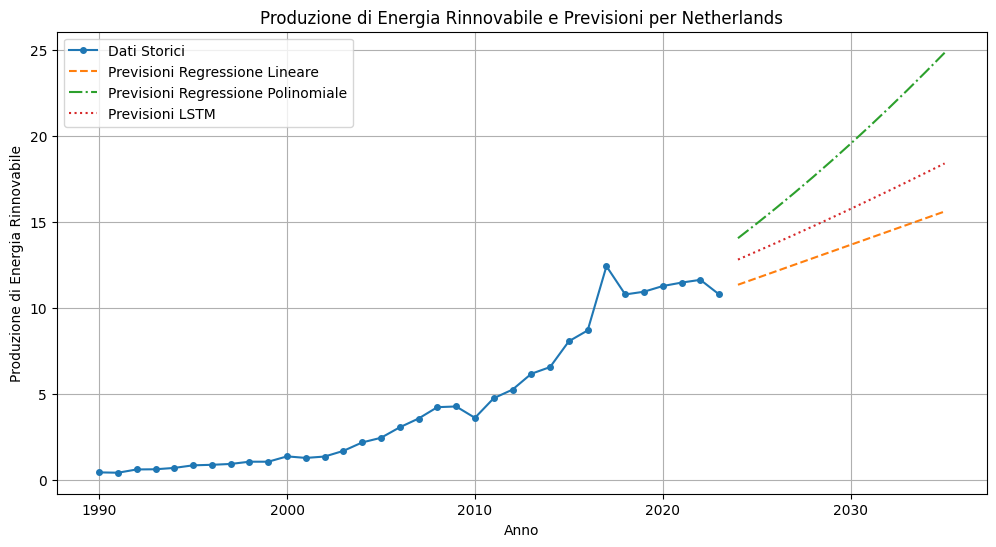

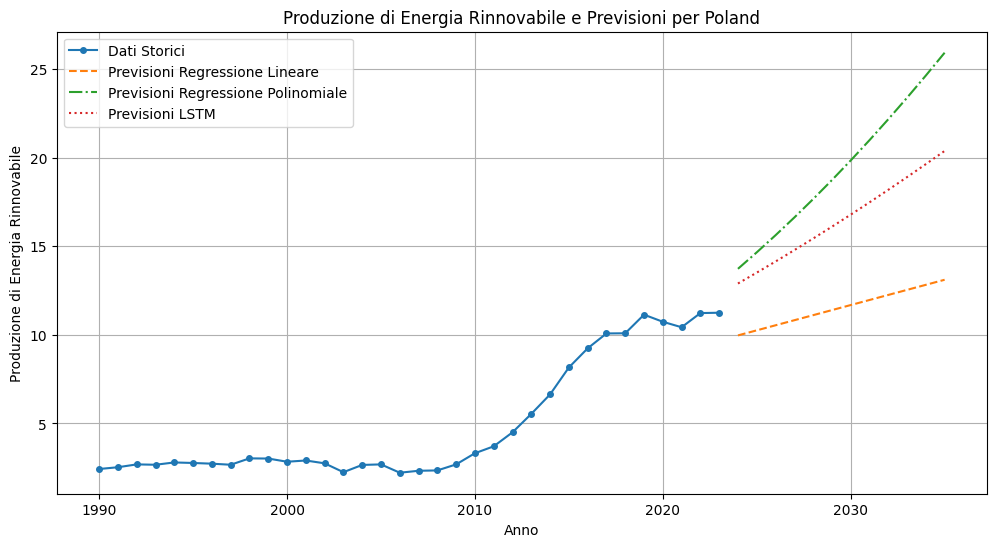

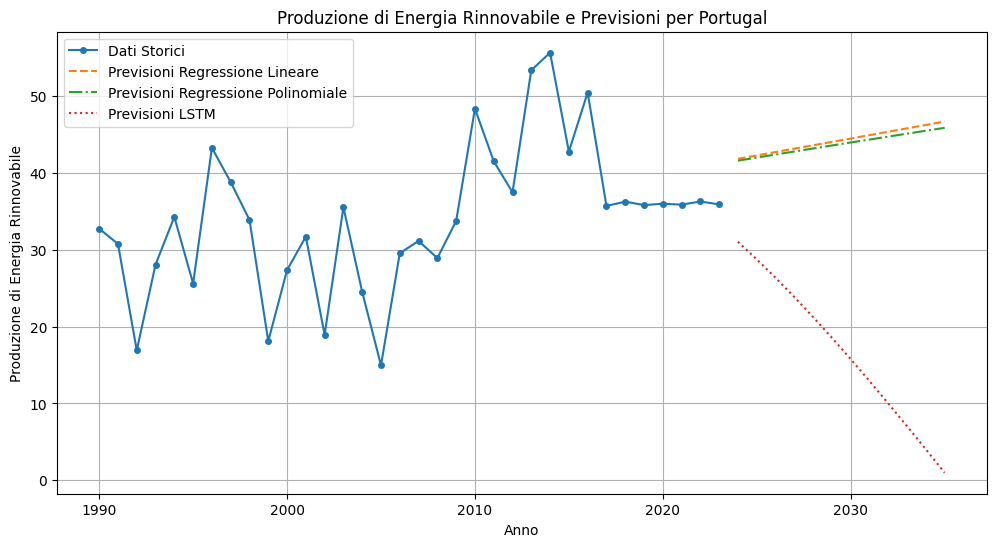

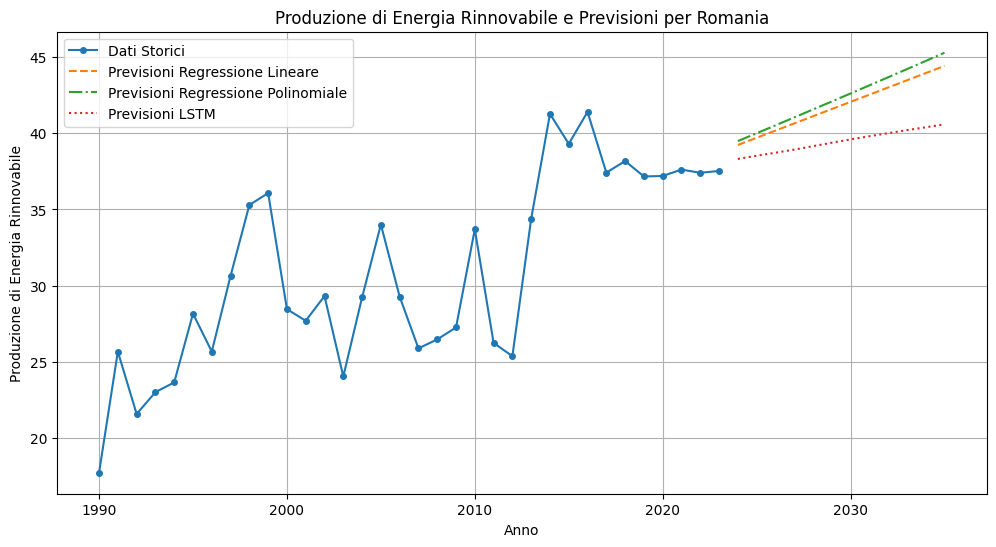

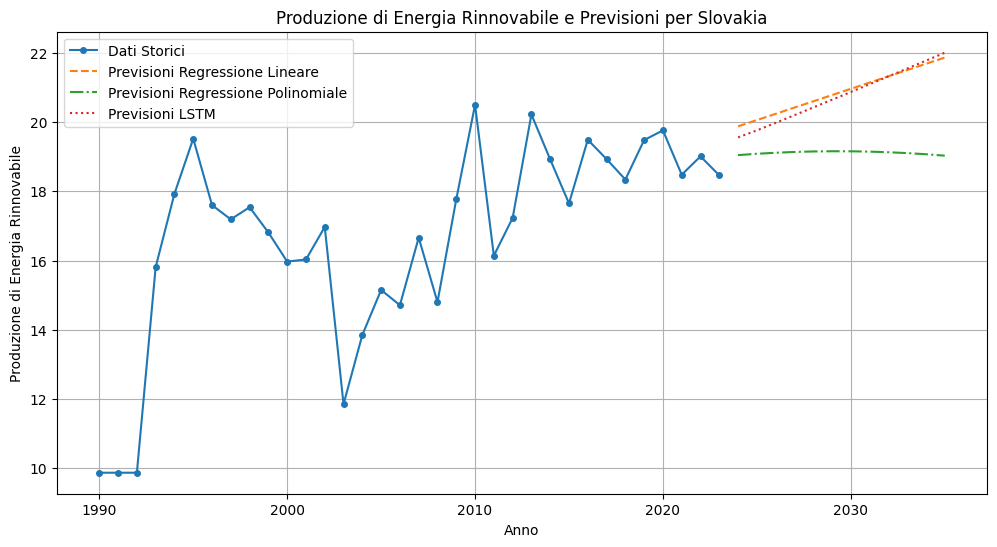

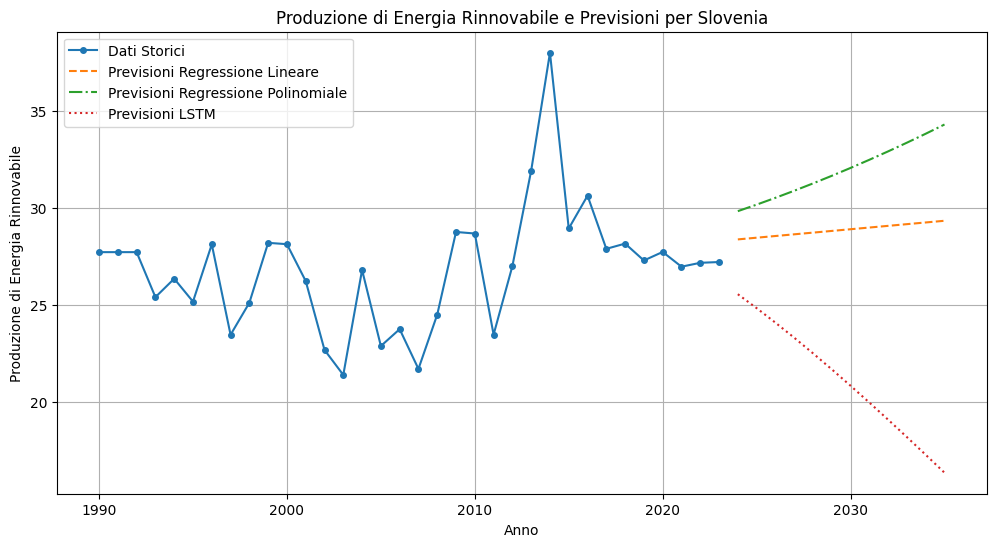

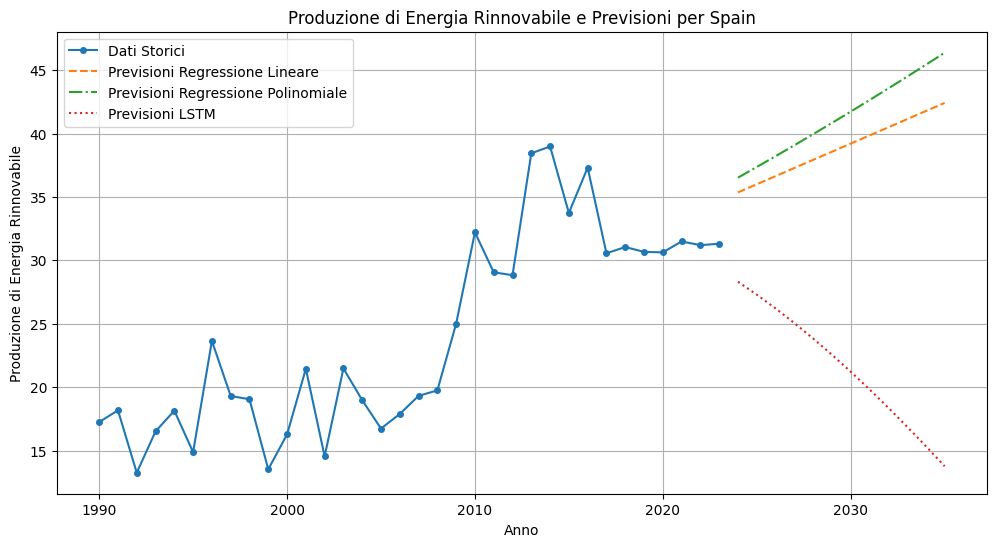

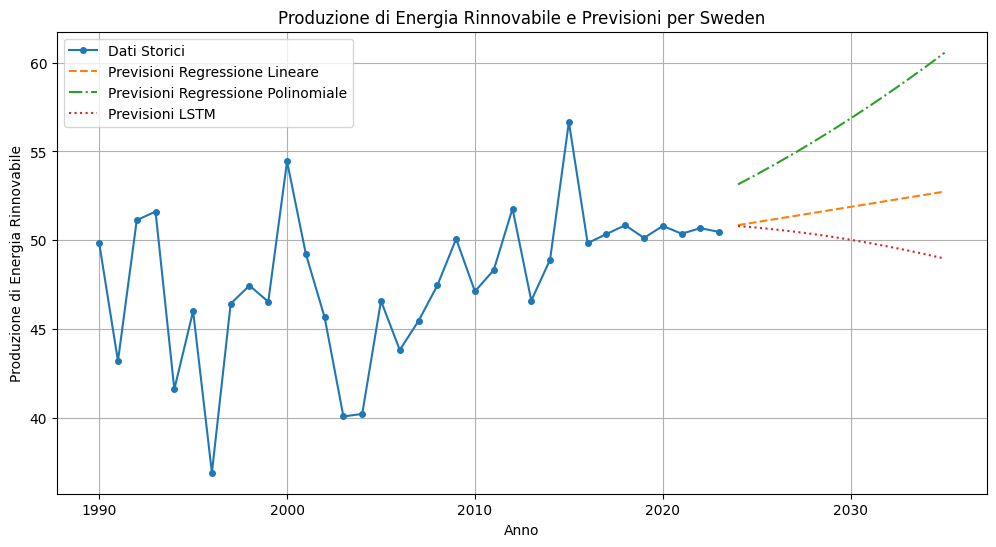

In [ ]:
import matplotlib.pyplot as plt

# Rinominare la colonna per permettere il merge corretto
df_eu_long_renamed = df_eu_long.rename(columns={'Country and area': 'Country'})

# Unire i dati storici con le previsioni per facilitare la visualizzazione
df_combined = pd.merge(df_eu_long_renamed, predictions_df, on=['Country', 'Year'], how='outer')

# Ordina per Anno per una corretta visualizzazione delle serie temporali
df_combined = df_combined.sort_values(by=['Country', 'Year'])

# Loop per generare un grafico per ogni paese
for country in df_combined['Country'].unique():
    plt.figure(figsize=(12, 6))
    df_country_plot = df_combined[df_combined['Country'] == country]

    # Dati storici
    plt.plot(df_country_plot['Year'], df_country_plot['Renewable Energy Production'], label='Dati Storici', marker='o', markersize=4)

    # Previsioni Linear Regression
    plt.plot(df_country_plot['Year'], df_country_plot['Linear_Regression_Prediction'], label='Previsioni Regressione Lineare', linestyle='--')

    # Previsioni Polynomial Regression
    plt.plot(df_country_plot['Year'], df_country_plot['Polynomial_Regression_Prediction'], label='Previsioni Regressione Polinomiale', linestyle='-.')

    # Previsioni LSTM
    plt.plot(df_country_plot['Year'], df_country_plot['LSTM_Prediction'], label='Previsioni LSTM', linestyle=':')

    plt.title(f'Produzione di Energia Rinnovabile e Previsioni per {country}')
    plt.xlabel('Anno')
    plt.ylabel('Produzione di Energia Rinnovabile')
    plt.legend()
    plt.grid(True)
    plt.show()